## Environment Setup

In [6]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import matplotlib.pyplot as plt

data_dir = "/content/drive/MyDrive/unet_project/data"
os.makedirs(data_dir, exist_ok=True)

# ISBI: download only if we don't have it yet
if not os.path.exists(f"{data_dir}/isbi2012"):
    !wget -q -O {data_dir}/ISBI-2012-challenge.zip https://downloads.imagej.net/ISBI-2012-challenge.zip
    !unzip -q {data_dir}/ISBI-2012-challenge.zip -d {data_dir}/isbi2012

# Pets: PyTorch downloads only if missing
from torchvision.datasets import OxfordIIITPet
pets = OxfordIIITPet(root="/content/data", split="trainval",
                     target_types="segmentation", download=True)
print("Data ready!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data ready!


## Week M1:

Data Lead:

Test Images

number of pets in this split: 3680
sizes of 5 photos: [(394, 500), (450, 313), (500, 465), (500, 351), (600, 363)]
mask shape: (500, 394) values: [1 2 3]


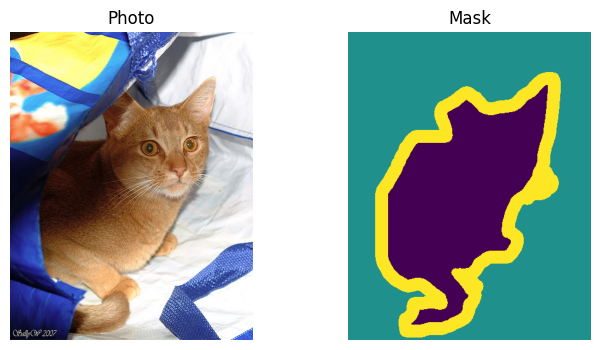

In [12]:
# Inspecting the Oxford Pets Dataset
img, mask = pets[0]
m = np.array(mask)
print("number of pets in this split:", len(pets))
print("sizes of 5 photos:", [pets[i][0].size for i in range(5)])
print("mask shape:", m.shape, "values:", np.unique(m))

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(img); ax[0].set_title("Photo")
ax[1].imshow(m);   ax[1].set_title("Mask")
for a in ax: a.axis("off")
plt.show()

['/content/drive/MyDrive/unet_project/data/isbi2012/train-volume.tif'] ['/content/drive/MyDrive/unet_project/data/isbi2012/train-labels.tif']
(30, 512, 512) (30, 512, 512)


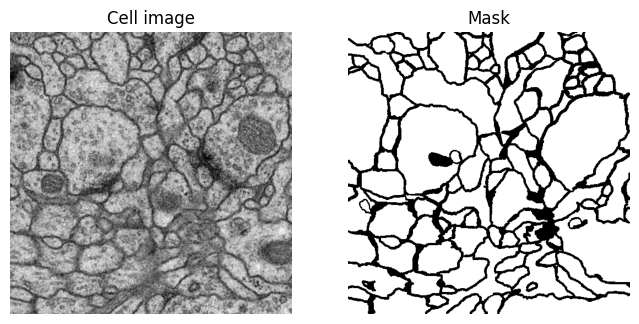

In [8]:
# Basic Loading of the ISBI-2012 Dataset
!pip install -q tifffile
import glob, tifffile

vol = glob.glob(f"{data_dir}/isbi2012/**/train-volume.tif", recursive=True)
lab = glob.glob(f"{data_dir}/isbi2012/**/train-labels.tif", recursive=True)
print(vol, lab)

images = tifffile.imread(vol[0])   # all 30 pictures
masks  = tifffile.imread(lab[0])   # their 30 masks
print(images.shape, masks.shape)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(images[0], cmap="gray"); ax[0].set_title("Cell image")
ax[1].imshow(masks[0],  cmap="gray"); ax[1].set_title("Mask")
for a in ax: a.axis("off")
plt.show()

images: (30, 512, 512) uint8 min/max: 0 255
masks : (30, 512, 512) uint8 values: [  0 255]


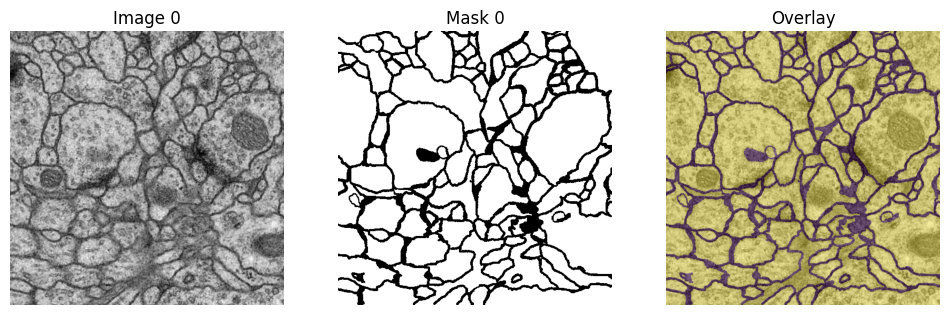

In [10]:
# Thorough Engineering Inspection of ISBI-2012
import numpy as np, glob, tifffile
import matplotlib.pyplot as plt

vol = glob.glob(f"{data_dir}/isbi2012/**/train-volume.tif", recursive=True)[0]
lab = glob.glob(f"{data_dir}/isbi2012/**/train-labels.tif", recursive=True)[0]
images = tifffile.imread(vol)
masks  = tifffile.imread(lab)

print("images:", images.shape, images.dtype, "min/max:", images.min(), images.max())
print("masks :", masks.shape, masks.dtype, "values:", np.unique(masks))

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(images[0], cmap="gray"); ax[0].set_title("Image 0")
ax[1].imshow(masks[0],  cmap="gray"); ax[1].set_title("Mask 0")
ax[2].imshow(images[0], cmap="gray"); ax[2].imshow(masks[0], alpha=0.4); ax[2].set_title("Overlay")
for a in ax: a.axis("off")
plt.show()

In [13]:
import json, random
from torchvision.datasets import OxfordIIITPet

pets_test = OxfordIIITPet(root="/content/data", split="test", target_types="segmentation", download=True)
print("pets trainval:", len(pets), " pets test:", len(pets_test))

# the split
split = {"isbi_train": list(range(0, 24)), "isbi_val": list(range(24, 30))}
idx = list(range(len(pets)))
random.Random(42).shuffle(idx)
cut = int(0.8 * len(idx))
split["pets_train"], split["pets_val"] = idx[:cut], idx[cut:]
with open(f"{data_dir}/split.json", "w") as f:
    json.dump(split, f)
print("pets train/check:", len(split["pets_train"]), len(split["pets_val"]))

# the numbers
train_imgs = images[:24].astype(np.float32) / 255.0
print("ISBI train mean: %.4f  std: %.4f" % (train_imgs.mean(), train_imgs.std()))
print("ISBI white (cell) pixels: train %.1f%%, check %.1f%%" %
      (100*(masks[:24] == 255).mean(), 100*(masks[24:] == 255).mean()))

counts = np.zeros(4)
for i in random.Random(0).sample(split["pets_train"], 200):
    m = np.array(pets[i][1])
    for v in (1, 2, 3):
        counts[v] += (m == v).sum()
print("Pets (200 random): pet %.1f%%, background %.1f%%, border %.1f%%" % tuple(100*counts[1:]/counts.sum()))

from google.colab import files
files.download(f"{data_dir}/split.json")

pets trainval: 3680  pets test: 3669
pets train/check: 2944 736
ISBI train mean: 0.4908  std: 0.1708
ISBI white (cell) pixels: train 77.5%, check 80.4%
Pets (200 random): pet 28.2%, background 60.9%, border 10.9%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>